Definí una transformación con transforms.Compose que achique la foto a 64×64 (Resize) y la convierta a tensor (ToTensor). Usamos 64 y no 256 porque en CPU entrenar con el tamaño completo tardaría horas.
Cargá ../data/tomate con datasets.ImageFolder, pasándole esa transformación.
Imprimí len(datos), datos.classes y el .shape de la primera imagen (datos[0][0]).

Resize =achica cada foto de 256×256 a 64×64, para que entrenar en CPU tarde minutos y no horas.
ToTensor= convierte la foto en un tensor, que es el arreglo de PyTorch (el equivalente al np.array que ya usaste), y pasa los valores de 0–255 a 0–1. Es la misma división por 255 que hiciste a mano en el notebook 03.
ImageFolder =recorre las carpetas y usa el nombre de cada una como etiqueta. datos[0] devuelve un par: la imagen y el número de su clase.

In [4]:
from torchvision import datasets, transforms 
transformacion=transforms.Compose([
    transforms.Resize((64,64)),
    transforms.ToTensor()
])
datos=datasets.ImageFolder("../data/tomate", transform=transformacion)

print (len(datos))
print(datos.classes)
print(datos[0][0].shape)

16011
['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
torch.Size([3, 64, 64])


In [5]:
import torch
from torch.utils.data import DataLoader, random_split  

generador= torch.Generator().manual_seed(42)
entreno, prueba = random_split(datos, [0.8, 0.2], generator=generador)

cargador_entreno= DataLoader(entreno, batch_size=32, shuffle=True)
cargador_prueba=DataLoader(prueba, batch_size=32)

print(len (entreno), len (prueba))

imagenes, etiquetas= next (iter(cargador_entreno))
print (imagenes.shape)
print (etiquetas)


12809 3202
torch.Size([32, 3, 64, 64])
tensor([4, 7, 3, 7, 1, 7, 3, 2, 6, 0, 6, 5, 5, 7, 4, 2, 1, 2, 2, 7, 7, 3, 6, 9,
        4, 4, 7, 9, 9, 6, 7, 7])


Ahora viene la CNN

In [6]:
from torch import nn

class RedTomate(nn.Module):
    def __init__(self):
        super().__init__()
        self.extractor = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.clasificador = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 10),
        )

    def forward(self, x):
        x = self.extractor(x)
        return self.clasificador(x)

red = RedTomate()
salida = red(imagenes)
print(salida.shape)

torch.Size([32, 10])


Qué significa [32, 10]
Entraron 32 fotos y salieron 10 puntajes por cada una, uno por clase. La red ya tiene la forma correcta de punta a punta; lo que le falta es aprender. Hoy sus filtros tienen números al azar, así que si la evaluaras acertaría más o menos 1 de cada 10, lo mismo que adivinar.

Todo esto ya lo hiciste a mano en el notebook 03; acá está apilado:

nn.Conv2d(3, 16, kernel_size=3, padding=1) son 16 filtros de 3×3, como el de bordes que escribiste vos. La diferencia es que acá nadie escribe los números del filtro: la red los aprende sola. Entran 3 canales (rojo, verde, azul) y salen 16, uno por filtro.
nn.ReLU() es el max(0, suma) de tu neurona: lo negativo pasa a cero.
nn.MaxPool2d(2) achica la imagen a la mitad, quedándose con el valor más alto de cada cuadradito de 2×2. La foto pasa de 64×64 a 32×32, y con el segundo a 16×16.
La segunda Conv2d(16, 32, ...) aplica 32 filtros sobre lo que encontraron los primeros 16. Los primeros detectan bordes y manchas de color; los segundos combinan eso en formas más complejas.
nn.Flatten() estira todo en una sola fila de números: 32 canales × 16 × 16 = 8.192.
nn.Linear(32 * 16 * 16, 10) son 10 neuronas, una por clase. Cada una da un puntaje; la clase con el puntaje más alto es la predicción.
forward define el recorrido: primero el extractor, después el clasificador.

In [7]:
print(salida[0])
print ("La red dice ", salida[0].argmax().item())
print("La clase real es:", etiquetas[0].item())

tensor([ 0.0384, -0.0554,  0.1868,  0.1035, -0.1132, -0.0654,  0.2173, -0.0891,
         0.0115,  0.0541], grad_fn=<SelectBackward0>)
La red dice  6
La clase real es: 4


Así se ve una red sin entrenar. Después del entrenamiento, el puntaje de la clase correcta debería quedar claramente por encima de los otros nuev

La primera línea muestra los 10 puntajes de la primera foto del lote; vas a ver números chicos y parecidos entre sí, sin ninguno que se destaque. La segunda dice qué clase eligió la red y la tercera cuál era la correcta. Lo más probable es que no coincidan.

Después de entrenar podés ejecutar la misma celda de nuevo y comparar. ¿Quedó más claro, o hay alguna parte que todavía no cierra

In [8]:
criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(red.parameters(), lr=0.001)

EPOCAS = 5

for epoca in range(EPOCAS):
    red.train()
    perdida_total = 0
    aciertos = 0

    for imagenes, etiquetas in cargador_entreno:
        salida = red(imagenes)
        perdida = criterio(salida, etiquetas)

        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()

        perdida_total += perdida.item()
        aciertos += (salida.argmax(dim=1) == etiquetas).sum().item()

    print(f"Época {epoca + 1}: pérdida {perdida_total / len(cargador_entreno):.3f}, "
          f"exactitud {aciertos / len(entreno):.3f}")

Época 1: pérdida 1.117, exactitud 0.626
Época 2: pérdida 0.589, exactitud 0.803
Época 3: pérdida 0.437, exactitud 0.854
Época 4: pérdida 0.358, exactitud 0.879
Época 5: pérdida 0.319, exactitud 0.893


Ahora se evalúa con las 3.202 fotos de prueba, que la red nunca vio. Escribí esto en una celda nueva:

In [9]:
from sklearn.metrics import accuracy_score, classification_report

red.eval()
reales = []
predichas = []

with torch.no_grad():
    for imagenes, etiquetas in cargador_prueba:
        salida = red(imagenes)
        predichas.extend(salida.argmax(dim=1).tolist())
        reales.extend(etiquetas.tolist())

print("Exactitud en prueba:", accuracy_score(reales, predichas))
print(classification_report(reales, predichas, target_names=datos.classes))

Exactitud en prueba: 0.8641474078700812
                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot       0.88      0.94      0.91       449
                        Tomato_Early_blight       0.63      0.71      0.67       195
                         Tomato_Late_blight       0.87      0.74      0.80       380
                           Tomato_Leaf_Mold       0.87      0.74      0.80       185
                  Tomato_Septoria_leaf_spot       0.78      0.92      0.85       345
Tomato_Spider_mites_Two_spotted_spider_mite       0.86      0.85      0.86       315
                        Tomato__Target_Spot       0.89      0.76      0.82       294
      Tomato__Tomato_YellowLeaf__Curl_Virus       0.97      0.92      0.94       660
                Tomato__Tomato_mosaic_virus       0.80      0.93      0.86        76
                             Tomato_healthy       0.89      0.98      0.94       303

                       

La nota de 0,896 que viste recién era sobre fotos que la red ya había visto cinco veces. Esta nueva es sobre fotos que nunca vio, así que es la que dice si aprendió de verdad o solo memorizó. Y es la que se compara con el 0,72 del Random Forest, porque esa también se sacó con fotos nunca vistas.



Para saber con qué confunde la red al virus del mosaico, armá la matriz de confusión

Text(0, 0.5, 'Clase real')

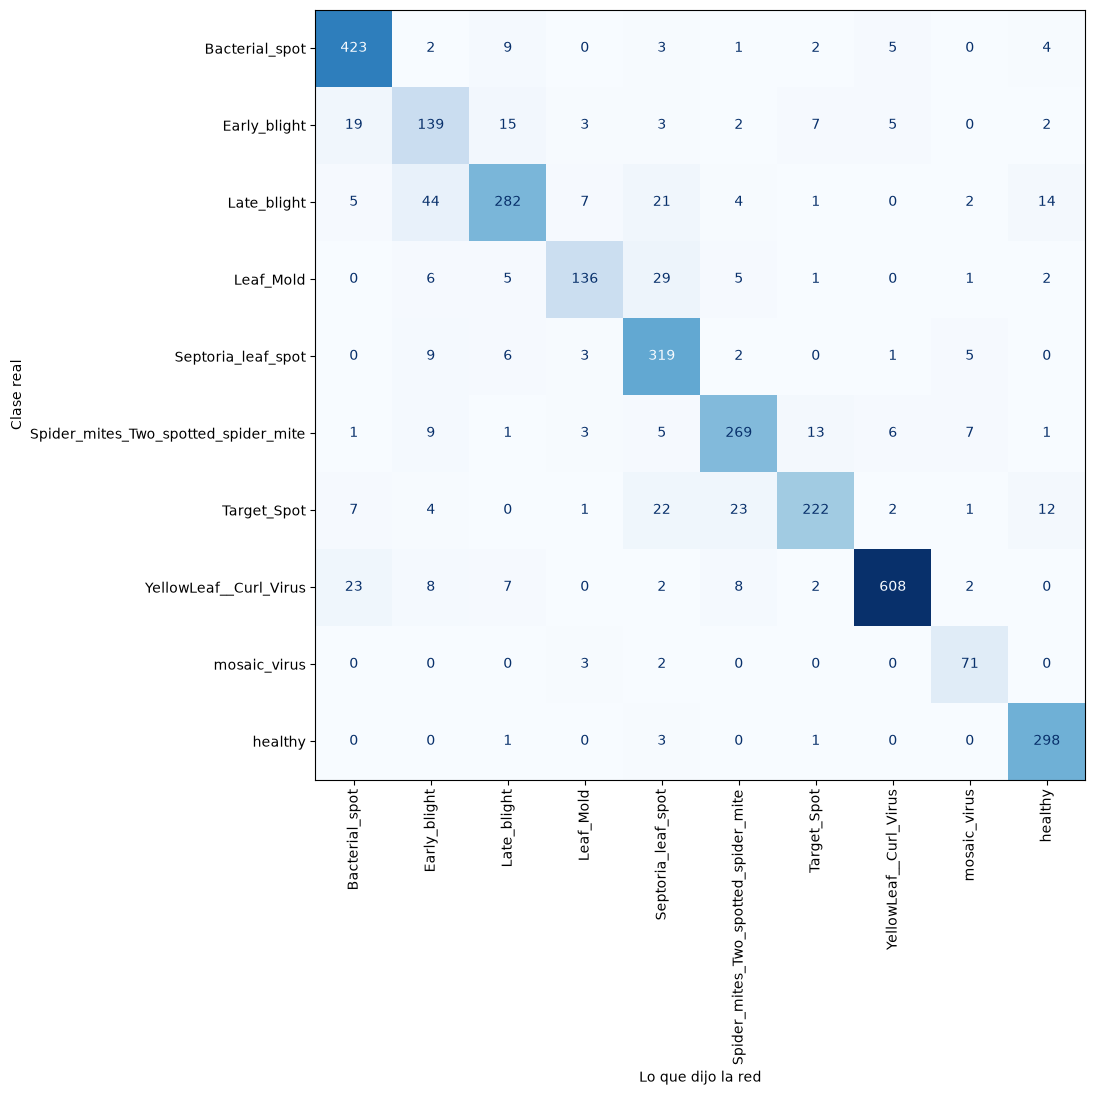

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

nombres = [c.replace("Tomato__Tomato_", "").replace("Tomato__", "").replace("Tomato_", "")
           for c in datos.classes]

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(
    reales, predichas,
    display_labels=nombres,
    xticks_rotation="vertical", cmap="Blues", colorbar=False, ax=ax,
)
ax.set_xlabel("Lo que dijo la red")
ax.set_ylabel("Clase real")

Por qué medir en cada época
En la clase anterior entrenaste 5 épocas y recién al final miraste la prueba. Eso deja una duda: ¿5 era poco, justo o demasiado? Para saberlo hay que mirar las dos notas, entrenamiento y prueba, después de cada época, y ver cómo se mueven:

Suben las dos: la red está aprendiendo cosas que sirven para fotos nuevas. Conviene seguir.
Entrenamiento sube y prueba se estanca o baja: la red empezó a memorizar las fotos de entrenamiento. Esto es el sobreajuste que te mencioné. Seguir entrenando a partir de ahí empeora la red

In [ ]:
def evaluar (red, cargador):
    red.eval()
    aciertos= 0
    total= 0
    with torch.no_grad():
        for imagenes, etiquetas in cargador:
            salida= red(imagenes)
            aciertos += (salida.argmax (dim=1) == etiquetas).sum ().item()
            total += len(etiquetas)
    return aciertos / total

torch.manual_seed(42)
red = RedTomate()
criterio= nn.CrossEntropyLoss()
optimizador= torch.optim.Adam(red.parameters(),lr=0.001)

EPOCAS= 10
historial= []

for epoca in range (EPOCAS):
    red.train()
    for imagenes, etiquetas in cargador_entreno:
        salida= red (imagenes)
        perdida= criterio (salida, etiquetas)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()

    exactitud_entreno= evaluar(red, cargador_entreno)
    exactitud_prueba=evaluar(red,cargador_prueba)
    historial.append({"epoca": epoca+1,
                      "entreno": exactitud_entreno,
                      "prueba": exactitud_prueba})
    print(f"Epoca{epoca+1}: entreno {exactitud_entreno:.3f},prueba{exactitud_prueba:.3f}")    

Epoca1: entreno 0.778,prueba0.758
Epoca2: entreno 0.865,prueba0.842
Epoca3: entreno 0.884,prueba0.861
Epoca4: entreno 0.921,prueba0.888
Epoca5: entreno 0.912,prueba0.872
Epoca6: entreno 0.929,prueba0.881
Epoca7: entreno 0.927,prueba0.881
Epoca8: entreno 0.946,prueba0.895
Epoca9: entreno 0.926,prueba0.869
Epoca10: entreno 0.956,prueba0.898


La celda de entrenamiento de la clase anterior te enseñó cómo aprende una red, con los cuatro pasos. La de evaluación te dio la primera nota real y la comparación con el Random Forest. Esta celda usa lo mismo, pero mide en cada época en vez de solo al final. Es como pasar de mirar la foto final de una carrera a mirar el video completo.

<Axes: title={'center': 'Exactitud por epoca'}, xlabel='epoca', ylabel='exactitud'>

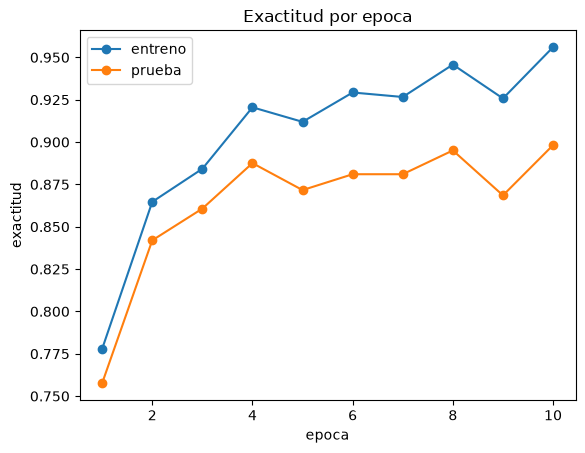

In [14]:
import  pandas as pd
curvas= pd.DataFrame(historial)
curvas.plot(x="epoca", y=["entreno","prueba"], marker="o", title= "Exactitud por epoca", ylabel="exactitud")

<Axes: title={'center': 'Exactitud por epoca'}, xlabel='epoca', ylabel='exactitud'>

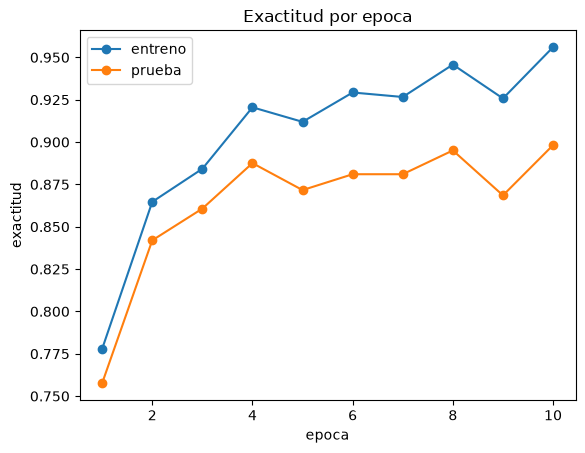

In [15]:
curvas.plot(x="epoca", y=["entreno", "prueba"], marker="o", title="Exactitud por epoca", ylabel="exactitud")